In [4]:
import numpy as np
import pandas as pd

In [5]:
#fetch and read the data
data_path = r"Dataset\heart_cleveland_upload.csv"
heart_df = pd.read_csv(data_path)
heart_df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,condition
0,69,1,0,160,234,1,2,131,0,0.1,1,1,0,0
1,69,0,0,140,239,0,0,151,0,1.8,0,2,0,0
2,66,0,0,150,226,0,0,114,0,2.6,2,0,0,0
3,65,1,0,138,282,1,2,174,0,1.4,1,1,0,1
4,64,1,0,110,211,0,2,144,1,1.8,1,0,0,0


In [6]:
heart_df.shape

(297, 14)

In [7]:
heart_df.count()

age          297
sex          297
cp           297
trestbps     297
chol         297
fbs          297
restecg      297
thalach      297
exang        297
oldpeak      297
slope        297
ca           297
thal         297
condition    297
dtype: int64

In [8]:
heart_df.describe()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,condition
count,297.000000,297.000000,297.000000,297.000000,297.000000,297.000000,297.000000,297.000000,297.000000,297.000000,297.000000,297.000000,297.000000,297.000000
mean,54.542088,0.676768,2.158249,131.693603,247.350168,0.144781,0.996633,149.599327,0.326599,1.055556,0.602694,0.676768,0.835017,0.461279
std,9.049736,0.468500,0.964859,17.762806,51.997583,0.352474,0.994914,22.941562,0.469761,1.166123,0.618187,0.938965,0.956690,0.499340
min,29.000000,0.000000,0.000000,94.000000,126.000000,0.000000,0.000000,71.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,48.000000,0.000000,2.000000,120.000000,211.000000,0.000000,0.000000,133.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,56.000000,1.000000,2.000000,130.000000,243.000000,0.000000,1.000000,153.000000,0.000000,0.800000,1.000000,0.000000,0.000000,0.000000
75%,61.000000,1.000000,3.000000,140.000000,276.000000,0.000000,2.000000,166.000000,1.000000,1.600000,1.000000,1.000000,2.000000,1.000000
max,77.000000,1.000000,3.000000,200.000000,564.000000,1.000000,2.000000,202.000000,1.000000,6.200000,2.000000,3.000000,2.000000,1.000000


In [9]:
heart_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 297 entries, 0 to 296
Data columns (total 14 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   age        297 non-null    int64  
 1   sex        297 non-null    int64  
 2   cp         297 non-null    int64  
 3   trestbps   297 non-null    int64  
 4   chol       297 non-null    int64  
 5   fbs        297 non-null    int64  
 6   restecg    297 non-null    int64  
 7   thalach    297 non-null    int64  
 8   exang      297 non-null    int64  
 9   oldpeak    297 non-null    float64
 10  slope      297 non-null    int64  
 11  ca         297 non-null    int64  
 12  thal       297 non-null    int64  
 13  condition  297 non-null    int64  
dtypes: float64(1), int64(13)
memory usage: 32.6 KB


In [10]:
heart_df.isna().sum()

age          0
sex          0
cp           0
trestbps     0
chol         0
fbs          0
restecg      0
thalach      0
exang        0
oldpeak      0
slope        0
ca           0
thal         0
condition    0
dtype: int64

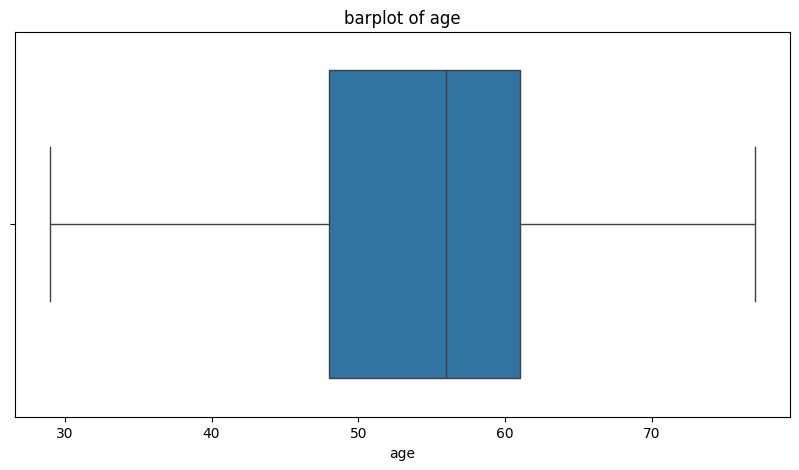

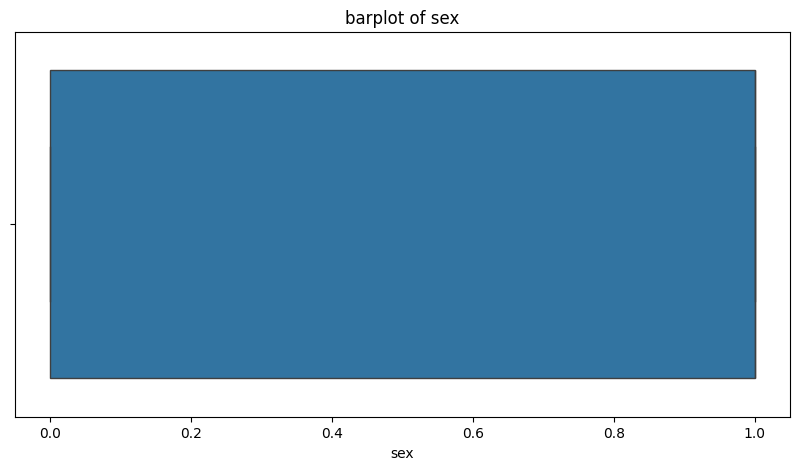

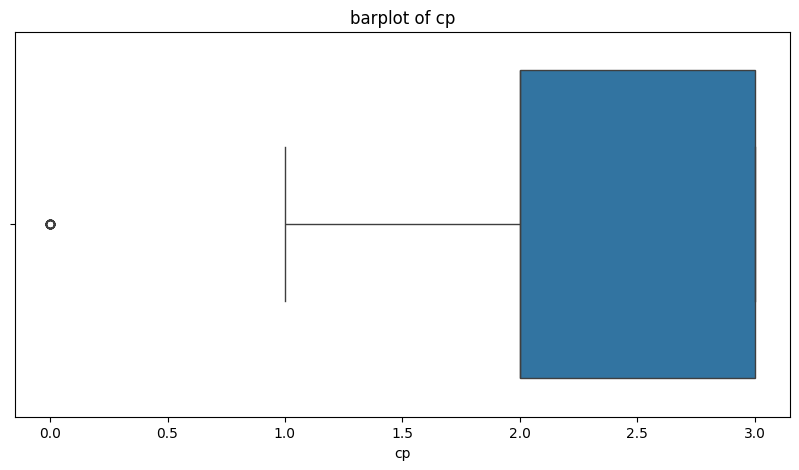

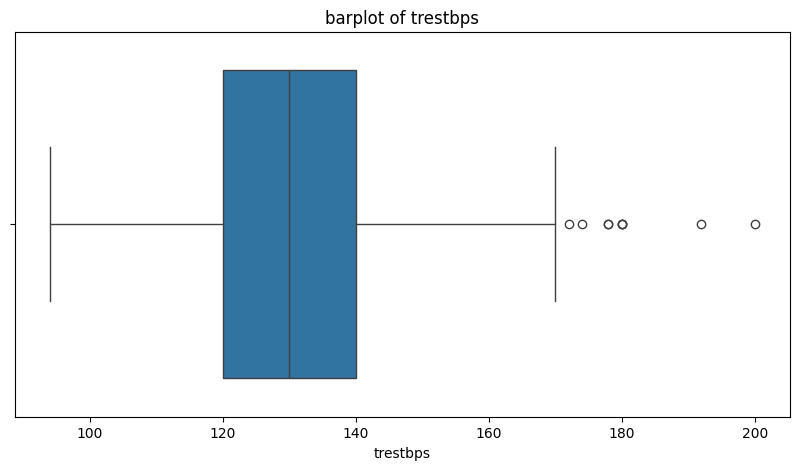

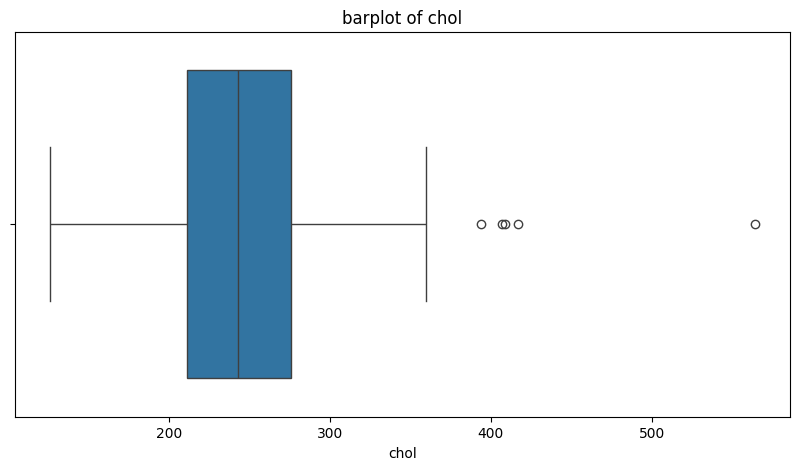

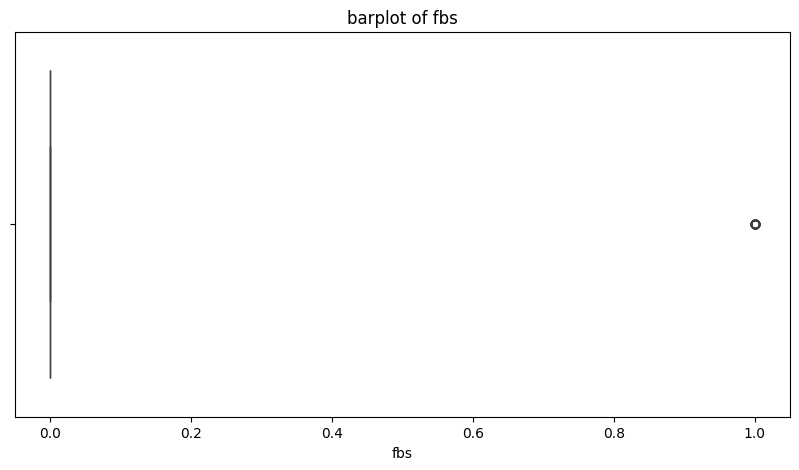

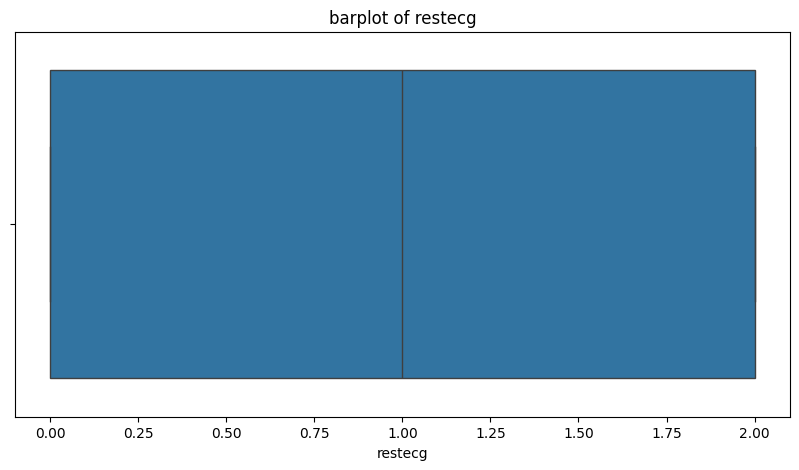

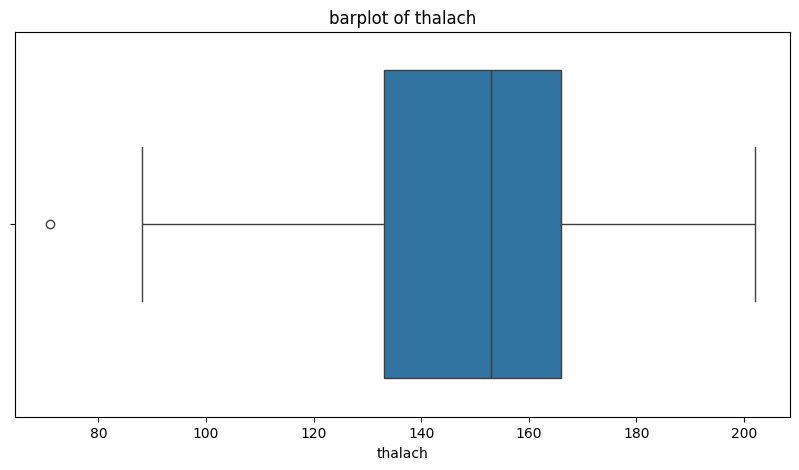

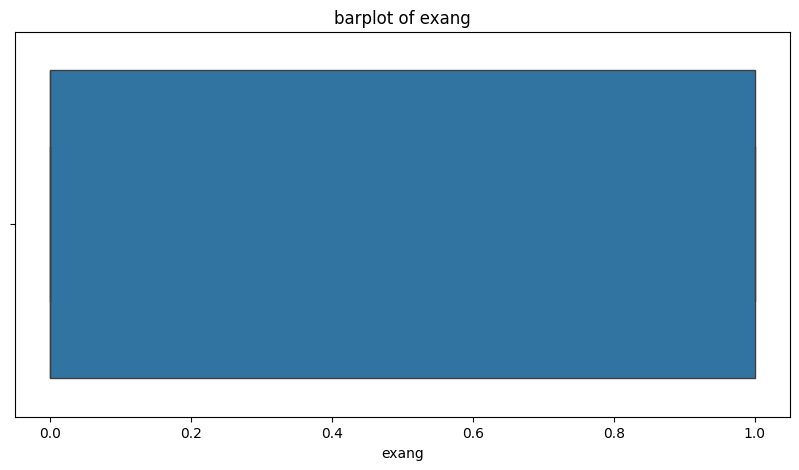

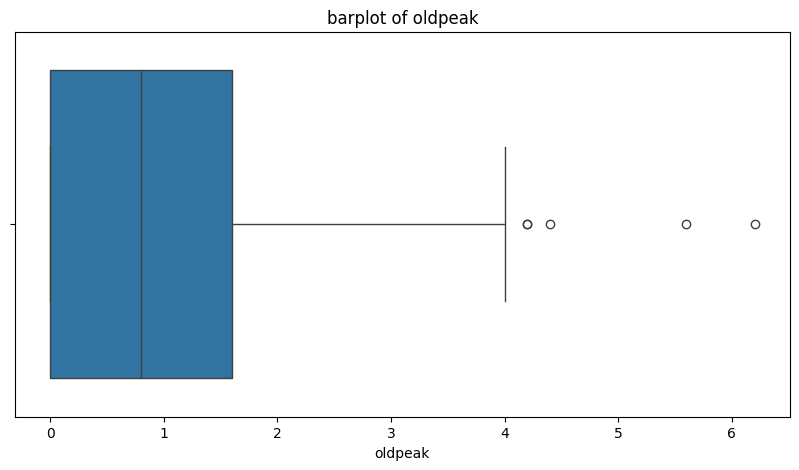

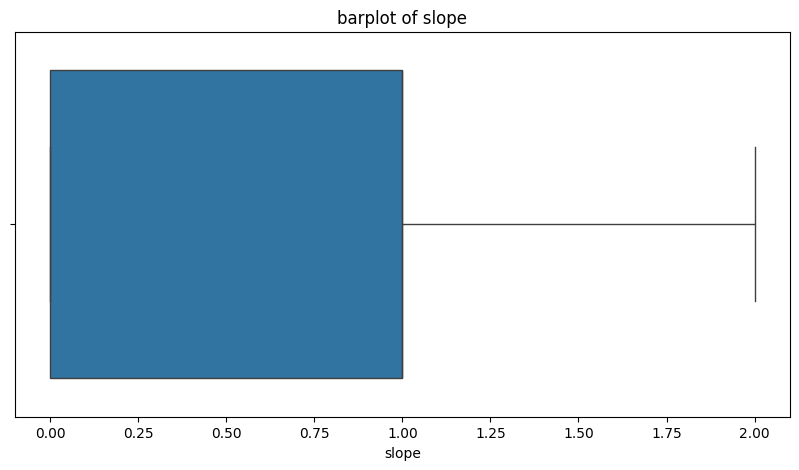

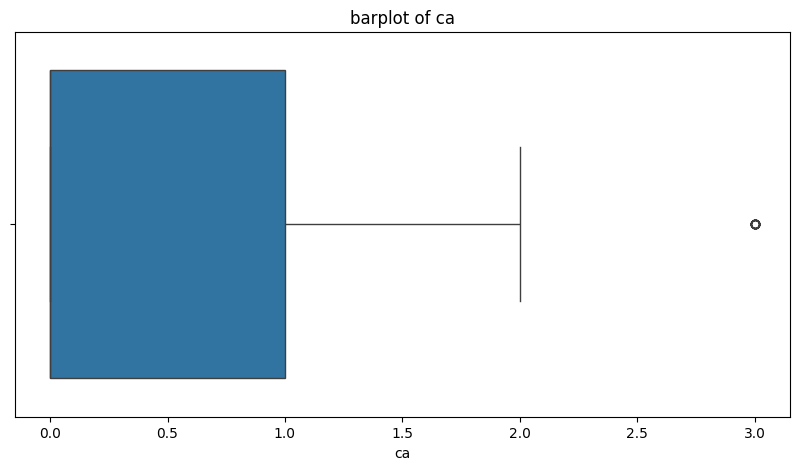

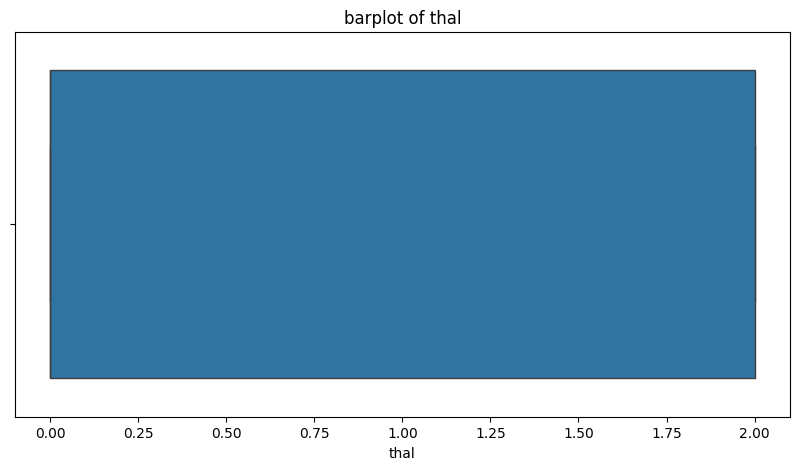

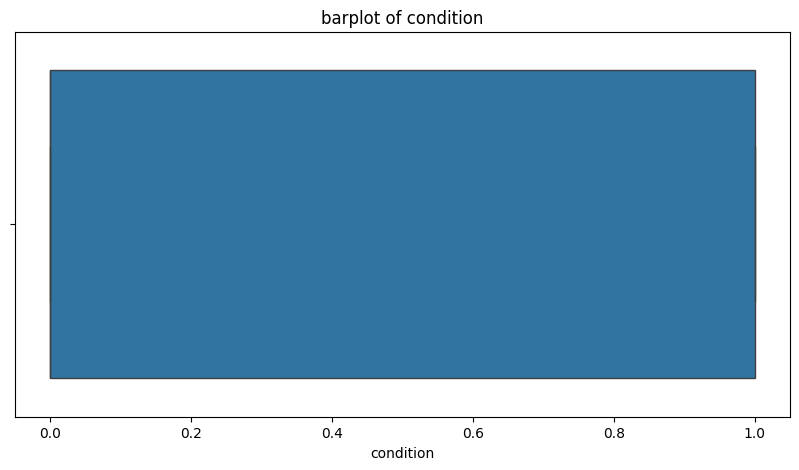

In [11]:
#checking for outliers in the data
import matplotlib.pyplot as plt
import seaborn as sns

#boxplot for each column
for column in heart_df.columns:
    plt.figure(figsize=(10,5))
    sns.boxplot(x=heart_df[column])
    plt.title(f'barplot of {column}')
    plt.show()

<Axes: xlabel='target', ylabel='count'>

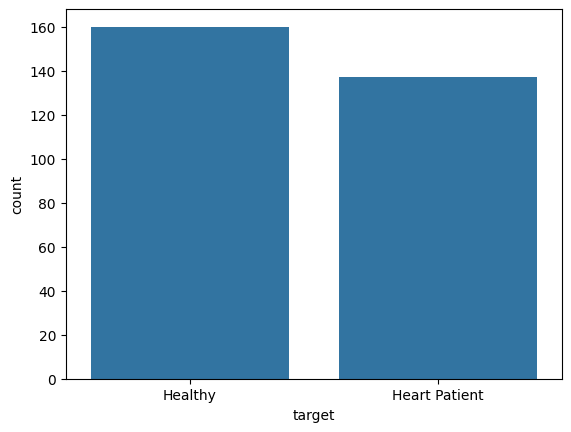

In [12]:
#Create a copy for visualization
heart_df_copy = heart_df.copy()
#comparing number of healthy vs number of heart patients in the dataset
heart_df_copy['target'] = heart_df_copy['condition'].map({0:'Healthy', 1:'Heart Patient'})
sns.countplot(x='target', data=heart_df_copy)


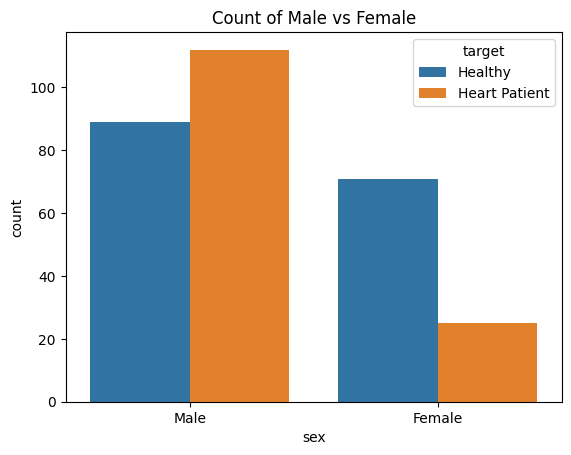

In [13]:
#comparing number of male vs female in the dataset
heart_df_copy['sex'] = heart_df_copy['sex'].map({0:'Female', 1:'Male'})
sns.countplot(x='sex', data=heart_df_copy,hue=heart_df_copy['target'])
plt.title('Count of Male vs Female')
plt.show()

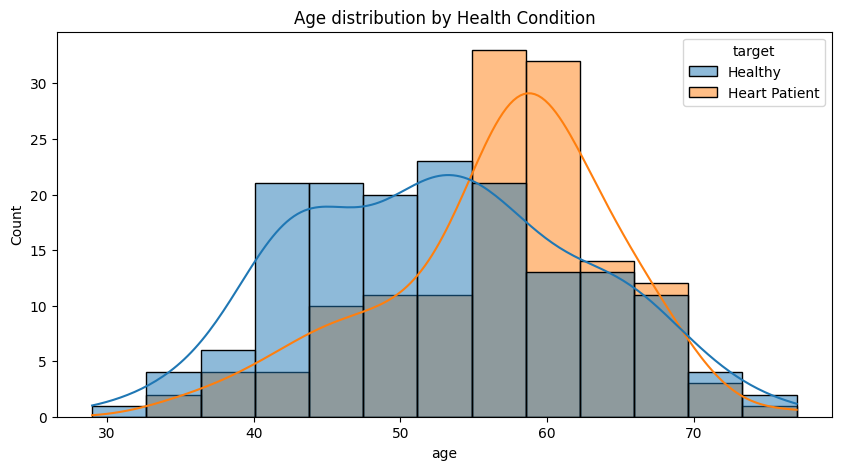

In [14]:
#compare age with health condition
plt.figure(figsize=(10,5))
sns.histplot(data=heart_df_copy, x='age', hue='target', kde=True)
plt.title('Age distribution by Health Condition')
plt.show()

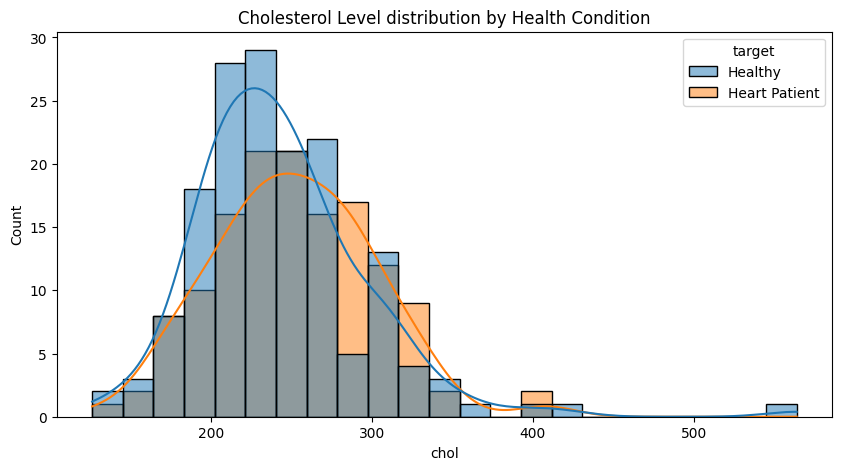

In [15]:
#compare cholesterol level with health condition
plt.figure(figsize=(10,5))
sns.histplot(data=heart_df_copy, x='chol', hue='target', kde=True)
plt.title('Cholesterol Level distribution by Health Condition')
plt.show()

In [16]:
#Divide the data frame into input and output
X = heart_df.drop('condition', axis=1)
y = heart_df['condition']
X.head()


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal
0,69,1,0,160,234,1,2,131,0,0.1,1,1,0
1,69,0,0,140,239,0,0,151,0,1.8,0,2,0
2,66,0,0,150,226,0,0,114,0,2.6,2,0,0
3,65,1,0,138,282,1,2,174,0,1.4,1,1,0
4,64,1,0,110,211,0,2,144,1,1.8,1,0,0


In [17]:
y.head()

0    0
1    0
2    0
3    1
4    0
Name: condition, dtype: int64

In [19]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

ImportError: Traceback (most recent call last):
  File "c:\Users\Mega-PC\AppData\Local\Programs\Python\Python312\Lib\site-packages\tensorflow\python\pywrap_tensorflow.py", line 73, in <module>
    from tensorflow.python._pywrap_tensorflow_internal import *
ImportError: DLL load failed while importing _pywrap_tensorflow_internal: Une routine d’initialisation d’une bibliothèque de liens dynamiques (DLL) a échoué.


Failed to load the native TensorFlow runtime.
See https://www.tensorflow.org/install/errors for some common causes and solutions.
If you need help, create an issue at https://github.com/tensorflow/tensorflow/issues and include the entire stack trace above this error message.

In [ ]:
#Defining the sequential model for binary classification
model = keras.Sequential()
model.add(layers.Dense(11, activation='relu', input_dim=13)) 
model.add(layers.Dense(1, activation='sigmoid'))  # Output layer for binary classification

C:\Users\Soulaiman\AppData\Roaming\Python\Python310\site-packages\keras\src\layers\core\dense.py:92: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [ ]:
#Compile and fit the model
model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
history = model.fit(X, y, epochs=300, batch_size=10, validation_split=0.22) 

Epoch 1/300
24/24 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.5931 - loss: 20.8807 - val_accuracy: 0.3485 - val_loss: 27.5972
Epoch 2/300
24/24 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.5931 - loss: 20.8807 - val_accuracy: 0.3485 - val_loss: 27.5972
Epoch 2/300
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.5931 - loss: 14.4903 - val_accuracy: 0.3485 - val_loss: 18.5963
Epoch 3/300
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.5931 - loss: 14.4903 - val_accuracy: 0.3485 - val_loss: 18.5963
Epoch 3/300
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.5931 - loss: 9.3746 - val_accuracy: 0.3485 - val_loss: 10.7171
Epoch 4/300
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.5931 - loss: 9.3746 - val_accuracy: 0.3485 - val_loss: 10.7171
Epoch 4/300
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.5931 - loss: 4.3046 - val_accuracy: 0.3485 - val_loss: 3.2069
Epoch 5/300
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.5931 - loss: 4.3046 - val_accuracy: 

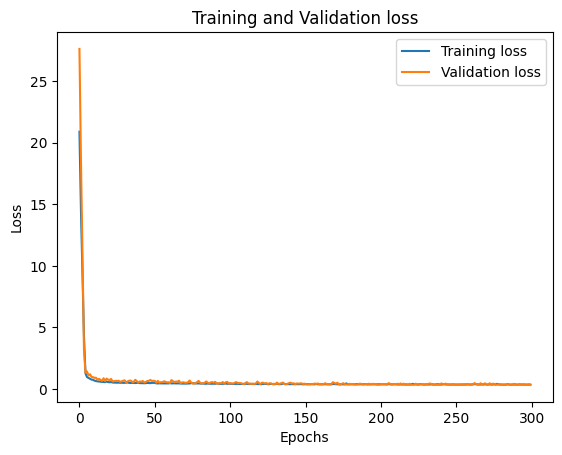

In [ ]:
#plotting training and validation loss
plt.plot(history.history['loss'], label='Training loss')
plt.plot(history.history['val_loss'], label='Validation loss')
plt.title('Training and Validation loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.show()

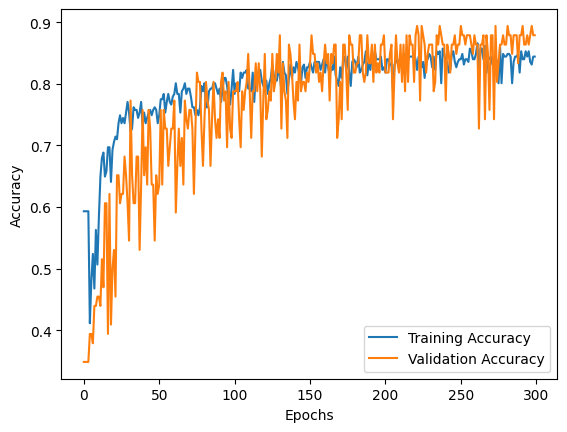

In [ ]:
#plotting training and validation accuracy
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

In [ ]:
import numpy as np
from numpy import array
#import 13 numbers
Xnew=array([67, 1, 0, 125, 254, 1, 1, 163, 0, 0.2, 1, 2, 1])
#Convert into numpy array 
Xnew = array(Xnew,dtype=np.float64)
#make prediction
ynew = ((model.predict(Xnew.reshape(1, -1))) > 0.5).astype("int32")
if ynew == 0:
    print("The person is Healthy")
else:
    print("The person is a Heart Patient")
    


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step
The person is Healthy
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step
The person is Healthy


In [1]:
#make graphiquel interface to take input from user and predict using the trained model
import tkinter as tk
from tkinter import messagebox
def predict_heart_disease():
    try:
        # Get input values from the user
        input_data = [float(entry.get()) for entry in entries]
        
        if len(input_data) != 13:
            messagebox.showerror("Input Error", "Please enter all 13 values.")
            return
        
        # Convert input data to numpy array and reshape for prediction
        input_array = np.array(input_data).reshape(1, -1)
        
        # Make prediction
        prediction = (model.predict(input_array) > 0.5).astype("int32")
        
        # Display result
        if prediction == 0:
            result = "The person is Healthy"
        else:
            result = "The person is a Heart Patient"
        
        messagebox.showinfo("Prediction Result", result)
    except ValueError:
        messagebox.showerror("Input Error", "Please enter valid numeric values.")
# Create the main window
root = tk.Tk()
root.title("Heart Disease Prediction")
# Create labels and entry fields for 13 inputs
labels = ["Age", "Sex", "Chest Pain Type", "Resting Blood Pressure", "Cholesterol",
          "Fasting Blood Sugar", "Resting ECG", "Max Heart Rate", "Exercise Induced Angina",
          "ST Depression", "Slope of ST", "Number of Major Vessels", "Thalassemia"]
entries = []
for i, label in enumerate(labels):
    tk.Label(root, text=label).grid(row=i, column=0)
    entry = tk.Entry(root)
    entry.grid(row=i, column=1)
    entries.append(entry)
# Create a button to trigger prediction
predict_button = tk.Button(root, text="Predict", command=predict_heart_disease)
predict_button.grid(row=len(labels), columnspan=2)
# Run the application
root.mainloop()

Exception in Tkinter callback
Traceback (most recent call last):
  File "c:\Python314\Lib\tkinter\__init__.py", line 2093, in __call__
    return self.func(*args)
           ~~~~~~~~~^^^^^^^
  File "C:\Users\Mega-PC\AppData\Local\Temp\ipykernel_30528\2837931850.py", line 14, in predict_heart_disease
    input_array = np.array(input_data).reshape(1, -1)
                  ^^
NameError: name 'np' is not defined
Exception in Tkinter callback
Traceback (most recent call last):
  File "c:\Python314\Lib\tkinter\__init__.py", line 2093, in __call__
    return self.func(*args)
           ~~~~~~~~~^^^^^^^
  File "C:\Users\Mega-PC\AppData\Local\Temp\ipykernel_30528\2837931850.py", line 14, in predict_heart_disease
    input_array = np.array(input_data).reshape(1, -1)
                  ^^
NameError: name 'np' is not defined
Exception in Tkinter callback
Traceback (most recent call last):
  File "c:\Python314\Lib\tkinter\__init__.py", line 2093, in __call__
    return self.func(*args)
           ~~